In [1]:
# importing pandas
import pandas as pd

In [2]:
# we will take input of raw data file
df = pd.read_csv("raw_data.csv")
df

,id,name,age,country,gender,income
0,1,John Doe,29.0,USA,Male,55000.0
1,1,John Doe,29.0,USA,Male,55000.0
2,2,Jane Smith,NaN,Canada,Female,62000.0
3,3,Alex,NaN,USA,Unknown,47000.0
4,4,Maria Garcia,34.0,Spain,Female,NaN
5,5,Li Wei,27.0,China,Male,51000.0
6,6,NaN,45.0,India,Female,73000.0
7,7,Ahmed Khan,38.0,NaN,Male,68000.0
8,8,Rachel Lee,29.0,USA,Female,62000.0
9,9,Carlos Ruiz,NaN,Mexico,Male,45000.0


In [3]:
# well as you can see that there is some values NaN means nothing is here so to see how many values are NaN we use 
# isNull() gives true when no value is there
df.isnull()

,id,name,age,country,gender,income
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,True,False,False,False
3,False,False,True,False,False,False
4,False,False,False,False,False,True
5,False,False,False,False,False,False
6,False,True,False,False,False,False
7,False,False,False,True,False,False
8,False,False,False,False,False,False
9,False,False,True,False,False,False


In [4]:
# now there is one more which does the same work
df.isna()

,id,name,age,country,gender,income
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,True,False,False,False
3,False,False,True,False,False,False
4,False,False,False,False,False,True
5,False,False,False,False,False,False
6,False,True,False,False,False,False
7,False,False,False,True,False,False
8,False,False,False,False,False,False
9,False,False,True,False,False,False


In [5]:
# now we want to count how many values are empty in our different columns so that we can know which variables can be used
# for feature selection or data analysis or are can they trusted becuase with lot of missing values it is hard to trust
df.isnull().sum() # this will count the null values

id         0
name       1
age        3
country    1
gender     1
income     1
dtype: int64

In [6]:
# now when we have counted it we want it to get dropped but this will drop the whole row in which
# there is a null value lets try it
df.dropna() # here we are left with only 4 rows

,id,name,age,country,gender,income
0,1,John Doe,29.0,USA,Male,55000.0
1,1,John Doe,29.0,USA,Male,55000.0
5,5,Li Wei,27.0,China,Male,51000.0
8,8,Rachel Lee,29.0,USA,Female,62000.0


In [7]:
# we can also drop the columns by just changing the axis
df.dropna(axis = 1)

,id
0,1
1,1
2,2
3,3
4,4
5,5
6,6
7,7
8,8
9,9


In [8]:
#  we can also fill it with some value lets fill it with average age in empty age cells
# we gonna make a copy of it
cleaned_data = df.copy()

In [9]:
cleaned_data["age"] = cleaned_data["age"].fillna(cleaned_data["age"].mean())
cleaned_data

,id,name,age,country,gender,income
0,1,John Doe,29.00,USA,Male,55000.0
1,1,John Doe,29.00,USA,Male,55000.0
2,2,Jane Smith,32.75,Canada,Female,62000.0
3,3,Alex,32.75,USA,Unknown,47000.0
4,4,Maria Garcia,34.00,Spain,Female,NaN
5,5,Li Wei,27.00,China,Male,51000.0
6,6,NaN,45.00,India,Female,73000.0
7,7,Ahmed Khan,38.00,NaN,Male,68000.0
8,8,Rachel Lee,29.00,USA,Female,62000.0
9,9,Carlos Ruiz,32.75,Mexico,Male,45000.0


In [10]:
# now we have ffill() for forward fill so this start from up and and if found NaN fill it with last valid value it sees
df.ffill()

,id,name,age,country,gender,income
0,1,John Doe,29.0,USA,Male,55000.0
1,1,John Doe,29.0,USA,Male,55000.0
2,2,Jane Smith,29.0,Canada,Female,62000.0
3,3,Alex,29.0,USA,Unknown,47000.0
4,4,Maria Garcia,34.0,Spain,Female,47000.0
5,5,Li Wei,27.0,China,Male,51000.0
6,6,Li Wei,45.0,India,Female,73000.0
7,7,Ahmed Khan,38.0,India,Male,68000.0
8,8,Rachel Lee,29.0,USA,Female,62000.0
9,9,Carlos Ruiz,29.0,Mexico,Male,45000.0


In [11]:
# in the same way we have bfill for backward fill, start from bottom and then if found NaN fill mit up with last valid value it sees
df.bfill()

,id,name,age,country,gender,income
0,1,John Doe,29.0,USA,Male,55000.0
1,1,John Doe,29.0,USA,Male,55000.0
2,2,Jane Smith,34.0,Canada,Female,62000.0
3,3,Alex,34.0,USA,Unknown,47000.0
4,4,Maria Garcia,34.0,Spain,Female,51000.0
5,5,Li Wei,27.0,China,Male,51000.0
6,6,Ahmed Khan,45.0,India,Female,73000.0
7,7,Ahmed Khan,38.0,USA,Male,68000.0
8,8,Rachel Lee,29.0,USA,Female,62000.0
9,9,Carlos Ruiz,31.0,Mexico,Male,45000.0


In [12]:
# now we will tackle the duplicated, so there can be a lot of duplicate values so it gives us true where there is a duplicate
# or it is seeing same thing twice
cleaned_data.duplicated()

0     False
1      True
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
dtype: bool

In [13]:
# we can see duplicated values for column
cleaned_data["country"].duplicated()

0     False
1      True
2     False
3      True
4     False
5     False
6     False
7     False
8      True
9     False
10     True
Name: country, dtype: bool

In [14]:
# we can see this for set of columns to see duplicated combinations
cleaned_data[["country", "gender"]].duplicated()

0     False
1      True
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
dtype: bool

In [15]:
# now we can see that we have duplictes so how about drop them
cleaned_data.drop_duplicates()
cleaned_data.drop_duplicates(inplace=True) # this can make changes directly in the data
cleaned_data #but still use the older way make a copy and then change it

,id,name,age,country,gender,income
0,1,John Doe,29.00,USA,Male,55000.0
2,2,Jane Smith,32.75,Canada,Female,62000.0
3,3,Alex,32.75,USA,Unknown,47000.0
4,4,Maria Garcia,34.00,Spain,Female,NaN
5,5,Li Wei,27.00,China,Male,51000.0
6,6,NaN,45.00,India,Female,73000.0
7,7,Ahmed Khan,38.00,NaN,Male,68000.0
8,8,Rachel Lee,29.00,USA,Female,62000.0
9,9,Carlos Ruiz,32.75,Mexico,Male,45000.0
10,10,Emily Davis,31.00,USA,NaN,58000.0


In [16]:
# we lost one row here
# so our data gets more cleaned

In [17]:
# now we see the datatypes and we can change it
# first see the datatypes
cleaned_data.dtypes

id           int64
name           str
age        float64
country        str
gender         str
income     float64
dtype: object

In [18]:
# seeing data type for the the column only
cleaned_data["age"].dtypes

dtype('float64')

In [19]:
# now we will cahnge there data type to int
# with  astype, we have already seen this
cleaned_data["age"] = cleaned_data["age"].astype("int64") # this will lose all the decimal part
cleaned_data.dtypes

id           int64
name           str
age          int64
country        str
gender         str
income     float64
dtype: object

In [20]:
# now it becomes int64 from float64
# we will see the datetime stamp and conversion to a data type which have a data
dt = pd.read_csv("globalAirQuality.csv")
dt

,timestamp,country,city,latitude,longitude,pm25,pm10,no2,so2,o3,co,aqi,temperature,humidity,wind_speed
0,2025-11-04 18:25:17.554219,US,New York,40.713,-74.006,50.295,108.938,27.998,6.539,52.568,1.096,108,18.504,70.168,3.725
1,2025-11-04 19:25:17.554219,US,New York,40.713,-74.006,32.083,63.043,36.120,4.021,43.536,1.075,90,5.838,80.088,8.969
2,2025-11-04 20:25:17.554219,US,New York,40.713,-74.006,42.250,82.553,26.935,9.538,23.320,0.977,84,31.833,62.783,9.650
3,2025-11-04 21:25:17.554219,US,New York,40.713,-74.006,30.403,79.951,63.536,7.609,31.369,0.230,158,23.140,89.153,8.956
4,2025-11-04 22:25:17.554219,US,New York,40.713,-74.006,21.083,66.423,38.997,6.919,45.615,1.085,97,13.632,76.499,4.017
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17995,2025-11-19 13:25:17.554219,CH,Zurich,47.377,8.542,27.899,74.179,41.474,6.677,50.869,1.028,103,7.079,52.443,7.452
17996,2025-11-19 14:25:17.554219,CH,Zurich,47.377,8.542,2.950,47.988,42.235,2.821,35.551,0.644,105,28.734,85.678,4.496
17997,2025-11-19 15:25:17.554219,CH,Zurich,47.377,8.542,61.347,72.908,46.976,5.763,66.492,0.947,122,21.951,72.311,9.660
17998,2025-11-19 16:25:17.554219,CH,Zurich,47.377,8.542,40.722,95.152,32.957,5.524,53.193,0.868,95,24.042,31.880,2.642


In [21]:
dt["timestamp"].dtypes

<StringDtype(na_value=nan)>

In [22]:
# first see this
date = "2026-10-20"
date_type = pd.Series(pd.to_datetime(date))
date_type.dtypes # now it become datatype datetime
# now lets change type of our timestamp
dt2 = dt.copy()

In [23]:
dt2

,timestamp,country,city,latitude,longitude,pm25,pm10,no2,so2,o3,co,aqi,temperature,humidity,wind_speed
0,2025-11-04 18:25:17.554219,US,New York,40.713,-74.006,50.295,108.938,27.998,6.539,52.568,1.096,108,18.504,70.168,3.725
1,2025-11-04 19:25:17.554219,US,New York,40.713,-74.006,32.083,63.043,36.120,4.021,43.536,1.075,90,5.838,80.088,8.969
2,2025-11-04 20:25:17.554219,US,New York,40.713,-74.006,42.250,82.553,26.935,9.538,23.320,0.977,84,31.833,62.783,9.650
3,2025-11-04 21:25:17.554219,US,New York,40.713,-74.006,30.403,79.951,63.536,7.609,31.369,0.230,158,23.140,89.153,8.956
4,2025-11-04 22:25:17.554219,US,New York,40.713,-74.006,21.083,66.423,38.997,6.919,45.615,1.085,97,13.632,76.499,4.017
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17995,2025-11-19 13:25:17.554219,CH,Zurich,47.377,8.542,27.899,74.179,41.474,6.677,50.869,1.028,103,7.079,52.443,7.452
17996,2025-11-19 14:25:17.554219,CH,Zurich,47.377,8.542,2.950,47.988,42.235,2.821,35.551,0.644,105,28.734,85.678,4.496
17997,2025-11-19 15:25:17.554219,CH,Zurich,47.377,8.542,61.347,72.908,46.976,5.763,66.492,0.947,122,21.951,72.311,9.660
17998,2025-11-19 16:25:17.554219,CH,Zurich,47.377,8.542,40.722,95.152,32.957,5.524,53.193,0.868,95,24.042,31.880,2.642


In [24]:
dt2["timestamp"] = pd.to_datetime(dt2["timestamp"])
dt2["timestamp"].dtypes # this is how we can change in the original data

dtype('<M8[us]')

In [25]:
# now we will see some string methods that how to deal with them
# first is lowercase conversion
cleaned_data["gender"].str.lower() # now these are for dtypes which are string

0        male
2      female
3     unknown
4      female
5        male
6      female
7        male
8      female
9        male
10        NaN
Name: gender, dtype: str

In [26]:
# uppercase
cleaned_data["gender"].str.upper()

0        MALE
2      FEMALE
3     UNKNOWN
4      FEMALE
5        MALE
6      FEMALE
7        MALE
8      FEMALE
9        MALE
10        NaN
Name: gender, dtype: str

In [27]:
# lets capitalize it
cleaned_data["gender"].str.capitalize()

0        Male
2      Female
3     Unknown
4      Female
5        Male
6      Female
7        Male
8      Female
9        Male
10        NaN
Name: gender, dtype: str

In [28]:
# then we have our strip method which will remove all blank spacese before and after
# which we have already seen
# the next is split which split values based on character
cleaned_data["name"].str.split(" ")

0         [John, Doe]
2       [Jane, Smith]
3              [Alex]
4     [Maria, Garcia]
5           [Li, Wei]
6                 NaN
7       [Ahmed, Khan]
8       [Rachel, Lee]
9      [Carlos, Ruiz]
10     [Emily, Davis]
Name: name, dtype: object

In [29]:
# now in this lecture the last is our contains which gives us true if the string if found present in the gives data
cleaned_data["country"].str.contains("India", case=False) # first is vale to be searched and then if want to ignore case make it false


0     False
2     False
3     False
4     False
5     False
6      True
7     False
8     False
9     False
10    False
Name: country, dtype: bool

In [30]:
# with case
cleaned_data["country"].str.contains("US")

0      True
2     False
3      True
4     False
5     False
6     False
7     False
8      True
9     False
10     True
Name: country, dtype: bool

In [31]:
df


,id,name,age,country,gender,income
0,1,John Doe,29.0,USA,Male,55000.0
1,1,John Doe,29.0,USA,Male,55000.0
2,2,Jane Smith,NaN,Canada,Female,62000.0
3,3,Alex,NaN,USA,Unknown,47000.0
4,4,Maria Garcia,34.0,Spain,Female,NaN
5,5,Li Wei,27.0,China,Male,51000.0
6,6,NaN,45.0,India,Female,73000.0
7,7,Ahmed Khan,38.0,NaN,Male,68000.0
8,8,Rachel Lee,29.0,USA,Female,62000.0
9,9,Carlos Ruiz,NaN,Mexico,Male,45000.0


In [32]:
# this is the end of pandas lecture 1

In [33]:
# Now we are starting our pandas lecture 2 from here

In [34]:
# Now we will discuss about data transforming and here we will do this
# suppose we want to add a new column with some information with some condition
# first is apply function which is a higher order function lets say we want to add a tax column into our clean data and 
# so if income is greater 50000 tax is 20% if income is less than 10%
cleaned_data["tax_in_%"] = cleaned_data["income"].apply(lambda income: 20 if income >= 50000 else 10 )
cleaned_data

,id,name,age,country,gender,income,tax_in_%
0,1,John Doe,29,USA,Male,55000.0,20
2,2,Jane Smith,32,Canada,Female,62000.0,20
3,3,Alex,32,USA,Unknown,47000.0,10
4,4,Maria Garcia,34,Spain,Female,NaN,10
5,5,Li Wei,27,China,Male,51000.0,20
6,6,NaN,45,India,Female,73000.0,20
7,7,Ahmed Khan,38,NaN,Male,68000.0,20
8,8,Rachel Lee,29,USA,Female,62000.0,20
9,9,Carlos Ruiz,32,Mexico,Male,45000.0,10
10,10,Emily Davis,31,USA,NaN,58000.0,20


In [35]:
# lets add income after tax
cleaned_data["income_after_tax"] = cleaned_data["income"] - ((cleaned_data["tax_in_%"]/100) * cleaned_data["income"])
cleaned_data

,id,name,age,country,gender,income,tax_in_%,income_after_tax
0,1,John Doe,29,USA,Male,55000.0,20,44000.0
2,2,Jane Smith,32,Canada,Female,62000.0,20,49600.0
3,3,Alex,32,USA,Unknown,47000.0,10,42300.0
4,4,Maria Garcia,34,Spain,Female,NaN,10,NaN
5,5,Li Wei,27,China,Male,51000.0,20,40800.0
6,6,NaN,45,India,Female,73000.0,20,58400.0
7,7,Ahmed Khan,38,NaN,Male,68000.0,20,54400.0
8,8,Rachel Lee,29,USA,Female,62000.0,20,49600.0
9,9,Carlos Ruiz,32,Mexico,Male,45000.0,10,40500.0
10,10,Emily Davis,31,USA,NaN,58000.0,20,46400.0


In [36]:
# Now we have our map function with which change the values to another form
gender = {
    "Male":"M", "Female":"F", "Unknown":"U"
}
cleaned_data["gender"] = cleaned_data["gender"].map(gender)
cleaned_data

,id,name,age,country,gender,income,tax_in_%,income_after_tax
0,1,John Doe,29,USA,M,55000.0,20,44000.0
2,2,Jane Smith,32,Canada,F,62000.0,20,49600.0
3,3,Alex,32,USA,U,47000.0,10,42300.0
4,4,Maria Garcia,34,Spain,F,NaN,10,NaN
5,5,Li Wei,27,China,M,51000.0,20,40800.0
6,6,NaN,45,India,F,73000.0,20,58400.0
7,7,Ahmed Khan,38,NaN,M,68000.0,20,54400.0
8,8,Rachel Lee,29,USA,F,62000.0,20,49600.0
9,9,Carlos Ruiz,32,Mexico,M,45000.0,10,40500.0
10,10,Emily Davis,31,USA,NaN,58000.0,20,46400.0


In [37]:
# now we have one more function which is used in transforming and that is assign()
# with assign we can create a new column and directly gives it the calculation to it
# remember we have to do a whole calculation for adding the income after tax
# now we add new income column
cleaned_data = cleaned_data.assign(new_income = cleaned_data["income"] * 1.1) # see how it is with assign and less complex
cleaned_data

,id,name,age,country,gender,income,tax_in_%,income_after_tax,new_income
0,1,John Doe,29,USA,M,55000.0,20,44000.0,60500.0
2,2,Jane Smith,32,Canada,F,62000.0,20,49600.0,68200.0
3,3,Alex,32,USA,U,47000.0,10,42300.0,51700.0
4,4,Maria Garcia,34,Spain,F,NaN,10,NaN,NaN
5,5,Li Wei,27,China,M,51000.0,20,40800.0,56100.0
6,6,NaN,45,India,F,73000.0,20,58400.0,80300.0
7,7,Ahmed Khan,38,NaN,M,68000.0,20,54400.0,74800.0
8,8,Rachel Lee,29,USA,F,62000.0,20,49600.0,68200.0
9,9,Carlos Ruiz,32,Mexico,M,45000.0,10,40500.0,49500.0
10,10,Emily Davis,31,USA,NaN,58000.0,20,46400.0,63800.0


In [38]:
# Now we have our replace so if you want to replace any value with something you can use this
# lets change usa with united states
cleaned_data["country"] = cleaned_data["country"].replace("USA", "United States")
cleaned_data

,id,name,age,country,gender,income,tax_in_%,income_after_tax,new_income
0,1,John Doe,29,United States,M,55000.0,20,44000.0,60500.0
2,2,Jane Smith,32,Canada,F,62000.0,20,49600.0,68200.0
3,3,Alex,32,United States,U,47000.0,10,42300.0,51700.0
4,4,Maria Garcia,34,Spain,F,NaN,10,NaN,NaN
5,5,Li Wei,27,China,M,51000.0,20,40800.0,56100.0
6,6,NaN,45,India,F,73000.0,20,58400.0,80300.0
7,7,Ahmed Khan,38,NaN,M,68000.0,20,54400.0,74800.0
8,8,Rachel Lee,29,United States,F,62000.0,20,49600.0,68200.0
9,9,Carlos Ruiz,32,Mexico,M,45000.0,10,40500.0,49500.0
10,10,Emily Davis,31,United States,NaN,58000.0,20,46400.0,63800.0


In [39]:
#  now we have our rename function so that we can change the names of our columns 
cleaned_data.columns = ["Id", "Name", "Age", "Country", "Gender", "Income", "Tax_In_%", "Income_After_Tax", "New_Income"]
cleaned_data

,Id,Name,Age,Country,Gender,Income,Tax_In_%,Income_After_Tax,New_Income
0,1,John Doe,29,United States,M,55000.0,20,44000.0,60500.0
2,2,Jane Smith,32,Canada,F,62000.0,20,49600.0,68200.0
3,3,Alex,32,United States,U,47000.0,10,42300.0,51700.0
4,4,Maria Garcia,34,Spain,F,NaN,10,NaN,NaN
5,5,Li Wei,27,China,M,51000.0,20,40800.0,56100.0
6,6,NaN,45,India,F,73000.0,20,58400.0,80300.0
7,7,Ahmed Khan,38,NaN,M,68000.0,20,54400.0,74800.0
8,8,Rachel Lee,29,United States,F,62000.0,20,49600.0,68200.0
9,9,Carlos Ruiz,32,Mexico,M,45000.0,10,40500.0,49500.0
10,10,Emily Davis,31,United States,NaN,58000.0,20,46400.0,63800.0


In [43]:
# but we have rename function also
cleaned_data = cleaned_data.rename(columns={"Income":"Salary"})
cleaned_data

,Id,Name,Age,Country,Gender,Salary,Tax_In_%,Income_After_Tax,New_Income
0,1,John Doe,29,United States,M,55000.0,20,44000.0,60500.0
2,2,Jane Smith,32,Canada,F,62000.0,20,49600.0,68200.0
3,3,Alex,32,United States,U,47000.0,10,42300.0,51700.0
4,4,Maria Garcia,34,Spain,F,NaN,10,NaN,NaN
5,5,Li Wei,27,China,M,51000.0,20,40800.0,56100.0
6,6,NaN,45,India,F,73000.0,20,58400.0,80300.0
7,7,Ahmed Khan,38,NaN,M,68000.0,20,54400.0,74800.0
8,8,Rachel Lee,29,United States,F,62000.0,20,49600.0,68200.0
9,9,Carlos Ruiz,32,Mexico,M,45000.0,10,40500.0,49500.0
10,10,Emily Davis,31,United States,NaN,58000.0,20,46400.0,63800.0


In [46]:
# we can also rename our labells or row names not index
cleaned_data = cleaned_data.rename(index={2:"Second"})
cleaned_data
cleaned_data = cleaned_data.rename(index={"Second":2})
cdt = cleaned_data.copy()

In [47]:
cdt

,Id,Name,Age,Country,Gender,Salary,Tax_In_%,Income_After_Tax,New_Income
0,1,John Doe,29,United States,M,55000.0,20,44000.0,60500.0
2,2,Jane Smith,32,Canada,F,62000.0,20,49600.0,68200.0
3,3,Alex,32,United States,U,47000.0,10,42300.0,51700.0
4,4,Maria Garcia,34,Spain,F,NaN,10,NaN,NaN
5,5,Li Wei,27,China,M,51000.0,20,40800.0,56100.0
6,6,NaN,45,India,F,73000.0,20,58400.0,80300.0
7,7,Ahmed Khan,38,NaN,M,68000.0,20,54400.0,74800.0
8,8,Rachel Lee,29,United States,F,62000.0,20,49600.0,68200.0
9,9,Carlos Ruiz,32,Mexico,M,45000.0,10,40500.0,49500.0
10,10,Emily Davis,31,United States,NaN,58000.0,20,46400.0,63800.0


In [48]:
# now we can sort the data based on any value
cdt.sort_values("Salary") # they are in ascending order

,Id,Name,Age,Country,Gender,Salary,Tax_In_%,Income_After_Tax,New_Income
9,9,Carlos Ruiz,32,Mexico,M,45000.0,10,40500.0,49500.0
3,3,Alex,32,United States,U,47000.0,10,42300.0,51700.0
5,5,Li Wei,27,China,M,51000.0,20,40800.0,56100.0
0,1,John Doe,29,United States,M,55000.0,20,44000.0,60500.0
10,10,Emily Davis,31,United States,NaN,58000.0,20,46400.0,63800.0
2,2,Jane Smith,32,Canada,F,62000.0,20,49600.0,68200.0
8,8,Rachel Lee,29,United States,F,62000.0,20,49600.0,68200.0
7,7,Ahmed Khan,38,NaN,M,68000.0,20,54400.0,74800.0
6,6,NaN,45,India,F,73000.0,20,58400.0,80300.0
4,4,Maria Garcia,34,Spain,F,NaN,10,NaN,NaN


In [53]:
# for descending order
cdt.sort_values("Salary", ascending=False)

,Id,Name,Age,Country,Gender,Salary,Tax_In_%,Income_After_Tax,New_Income
6,6,NaN,45,India,F,73000.0,20,58400.0,80300.0
7,7,Ahmed Khan,38,NaN,M,68000.0,20,54400.0,74800.0
8,8,Rachel Lee,29,United States,F,62000.0,20,49600.0,68200.0
2,2,Jane Smith,32,Canada,F,62000.0,20,49600.0,68200.0
10,10,Emily Davis,31,United States,NaN,58000.0,20,46400.0,63800.0
0,1,John Doe,29,United States,M,55000.0,20,44000.0,60500.0
5,5,Li Wei,27,China,M,51000.0,20,40800.0,56100.0
3,3,Alex,32,United States,U,47000.0,10,42300.0,51700.0
9,9,Carlos Ruiz,32,Mexico,M,45000.0,10,40500.0,49500.0
4,4,Maria Garcia,34,Spain,F,NaN,10,NaN,NaN


In [54]:
# you can have sorted columns with this also
cdt["Salary"].sort_values()

9     45000.0
3     47000.0
5     51000.0
0     55000.0
10    58000.0
2     62000.0
8     62000.0
7     68000.0
6     73000.0
4         NaN
Name: Salary, dtype: float64

In [55]:
# now when you sort them with someindexes lets say salry then have one more column then
cdt.sort_values(["Salary", "Age"])

,Id,Name,Age,Country,Gender,Salary,Tax_In_%,Income_After_Tax,New_Income
9,9,Carlos Ruiz,32,Mexico,M,45000.0,10,40500.0,49500.0
3,3,Alex,32,United States,U,47000.0,10,42300.0,51700.0
5,5,Li Wei,27,China,M,51000.0,20,40800.0,56100.0
0,1,John Doe,29,United States,M,55000.0,20,44000.0,60500.0
10,10,Emily Davis,31,United States,NaN,58000.0,20,46400.0,63800.0
8,8,Rachel Lee,29,United States,F,62000.0,20,49600.0,68200.0
2,2,Jane Smith,32,Canada,F,62000.0,20,49600.0,68200.0
7,7,Ahmed Khan,38,NaN,M,68000.0,20,54400.0,74800.0
6,6,NaN,45,India,F,73000.0,20,58400.0,80300.0
4,4,Maria Garcia,34,Spain,F,NaN,10,NaN,NaN


In [57]:
# we can sort them based on indexes
sdt = cdt.sort_values(["Salary", "Age"])
sdt

,Id,Name,Age,Country,Gender,Salary,Tax_In_%,Income_After_Tax,New_Income
9,9,Carlos Ruiz,32,Mexico,M,45000.0,10,40500.0,49500.0
3,3,Alex,32,United States,U,47000.0,10,42300.0,51700.0
5,5,Li Wei,27,China,M,51000.0,20,40800.0,56100.0
0,1,John Doe,29,United States,M,55000.0,20,44000.0,60500.0
10,10,Emily Davis,31,United States,NaN,58000.0,20,46400.0,63800.0
8,8,Rachel Lee,29,United States,F,62000.0,20,49600.0,68200.0
2,2,Jane Smith,32,Canada,F,62000.0,20,49600.0,68200.0
7,7,Ahmed Khan,38,NaN,M,68000.0,20,54400.0,74800.0
6,6,NaN,45,India,F,73000.0,20,58400.0,80300.0
4,4,Maria Garcia,34,Spain,F,NaN,10,NaN,NaN


In [58]:
sdt.sort_index()

,Id,Name,Age,Country,Gender,Salary,Tax_In_%,Income_After_Tax,New_Income
0,1,John Doe,29,United States,M,55000.0,20,44000.0,60500.0
2,2,Jane Smith,32,Canada,F,62000.0,20,49600.0,68200.0
3,3,Alex,32,United States,U,47000.0,10,42300.0,51700.0
4,4,Maria Garcia,34,Spain,F,NaN,10,NaN,NaN
5,5,Li Wei,27,China,M,51000.0,20,40800.0,56100.0
6,6,NaN,45,India,F,73000.0,20,58400.0,80300.0
7,7,Ahmed Khan,38,NaN,M,68000.0,20,54400.0,74800.0
8,8,Rachel Lee,29,United States,F,62000.0,20,49600.0,68200.0
9,9,Carlos Ruiz,32,Mexico,M,45000.0,10,40500.0,49500.0
10,10,Emily Davis,31,United States,NaN,58000.0,20,46400.0,63800.0


In [75]:
# if we keep our data sorted with salary our labells gets mixed up and not alligned so we have reset_index we give them new 
# indexes and preserve these old ones
sdt = sdt.reset_index()
sdt # now we have new index starting from zero


,Id,Name,Age,Country,Gender,Salary,Tax_In_%,Income_After_Tax,New_Income,Ranking
0,9,Carlos Ruiz,32,Mexico,M,45000.0,10,40500.0,49500.0,1.0
1,3,Alex,32,United States,U,47000.0,10,42300.0,51700.0,2.0
2,5,Li Wei,27,China,M,51000.0,20,40800.0,56100.0,3.0
3,1,John Doe,29,United States,M,55000.0,20,44000.0,60500.0,4.0
4,10,Emily Davis,31,United States,NaN,58000.0,20,46400.0,63800.0,5.0
5,8,Rachel Lee,29,United States,F,62000.0,20,49600.0,68200.0,7.0
6,2,Jane Smith,32,Canada,F,62000.0,20,49600.0,68200.0,7.0
7,7,Ahmed Khan,38,NaN,M,68000.0,20,54400.0,74800.0,8.0
8,6,NaN,45,India,F,73000.0,20,58400.0,80300.0,9.0
9,4,Maria Garcia,34,Spain,F,NaN,10,NaN,NaN,NaN


In [65]:
sdt = sdt.drop("index", axis=1)
sdt

,Id,Name,Age,Country,Gender,Salary,Tax_In_%,Income_After_Tax,New_Income
0,9,Carlos Ruiz,32,Mexico,M,45000.0,10,40500.0,49500.0
1,3,Alex,32,United States,U,47000.0,10,42300.0,51700.0
2,5,Li Wei,27,China,M,51000.0,20,40800.0,56100.0
3,1,John Doe,29,United States,M,55000.0,20,44000.0,60500.0
4,10,Emily Davis,31,United States,NaN,58000.0,20,46400.0,63800.0
5,8,Rachel Lee,29,United States,F,62000.0,20,49600.0,68200.0
6,2,Jane Smith,32,Canada,F,62000.0,20,49600.0,68200.0
7,7,Ahmed Khan,38,NaN,M,68000.0,20,54400.0,74800.0
8,6,NaN,45,India,F,73000.0,20,58400.0,80300.0
9,4,Maria Garcia,34,Spain,F,NaN,10,NaN,NaN


In [66]:
# lets now reset again and this time suppose if we do not want to preserve older index then we can use
sdt = sdt.reset_index(drop=True)
sdt # now we have new data but this one is preserved

,Id,Name,Age,Country,Gender,Salary,Tax_In_%,Income_After_Tax,New_Income
0,9,Carlos Ruiz,32,Mexico,M,45000.0,10,40500.0,49500.0
1,3,Alex,32,United States,U,47000.0,10,42300.0,51700.0
2,5,Li Wei,27,China,M,51000.0,20,40800.0,56100.0
3,1,John Doe,29,United States,M,55000.0,20,44000.0,60500.0
4,10,Emily Davis,31,United States,NaN,58000.0,20,46400.0,63800.0
5,8,Rachel Lee,29,United States,F,62000.0,20,49600.0,68200.0
6,2,Jane Smith,32,Canada,F,62000.0,20,49600.0,68200.0
7,7,Ahmed Khan,38,NaN,M,68000.0,20,54400.0,74800.0
8,6,NaN,45,India,F,73000.0,20,58400.0,80300.0
9,4,Maria Garcia,34,Spain,F,NaN,10,NaN,NaN


In [68]:
# now we can rank it also as ranking is possible here
# lets rank it based on salary
sdt["Ranking"] = sdt["Salary"].rank()
sdt

,Id,Name,Age,Country,Gender,Salary,Tax_In_%,Income_After_Tax,New_Income,Ranking
0,9,Carlos Ruiz,32,Mexico,M,45000.0,10,40500.0,49500.0,1.0
1,3,Alex,32,United States,U,47000.0,10,42300.0,51700.0,2.0
2,5,Li Wei,27,China,M,51000.0,20,40800.0,56100.0,3.0
3,1,John Doe,29,United States,M,55000.0,20,44000.0,60500.0,4.0
4,10,Emily Davis,31,United States,NaN,58000.0,20,46400.0,63800.0,5.0
5,8,Rachel Lee,29,United States,F,62000.0,20,49600.0,68200.0,6.5
6,2,Jane Smith,32,Canada,F,62000.0,20,49600.0,68200.0,6.5
7,7,Ahmed Khan,38,NaN,M,68000.0,20,54400.0,74800.0,8.0
8,6,NaN,45,India,F,73000.0,20,58400.0,80300.0,9.0
9,4,Maria Garcia,34,Spain,F,NaN,10,NaN,NaN,NaN


In [69]:
# descending order
sdt["Ranking"] = sdt["Salary"].rank(ascending=False)
sdt

,Id,Name,Age,Country,Gender,Salary,Tax_In_%,Income_After_Tax,New_Income,Ranking
0,9,Carlos Ruiz,32,Mexico,M,45000.0,10,40500.0,49500.0,9.0
1,3,Alex,32,United States,U,47000.0,10,42300.0,51700.0,8.0
2,5,Li Wei,27,China,M,51000.0,20,40800.0,56100.0,7.0
3,1,John Doe,29,United States,M,55000.0,20,44000.0,60500.0,6.0
4,10,Emily Davis,31,United States,NaN,58000.0,20,46400.0,63800.0,5.0
5,8,Rachel Lee,29,United States,F,62000.0,20,49600.0,68200.0,3.5
6,2,Jane Smith,32,Canada,F,62000.0,20,49600.0,68200.0,3.5
7,7,Ahmed Khan,38,NaN,M,68000.0,20,54400.0,74800.0,2.0
8,6,NaN,45,India,F,73000.0,20,58400.0,80300.0,1.0
9,4,Maria Garcia,34,Spain,F,NaN,10,NaN,NaN,NaN


In [70]:
# only integer part values in rank
sdt["Ranking"] = sdt["Salary"].rank(method="dense")
sdt

,Id,Name,Age,Country,Gender,Salary,Tax_In_%,Income_After_Tax,New_Income,Ranking
0,9,Carlos Ruiz,32,Mexico,M,45000.0,10,40500.0,49500.0,1.0
1,3,Alex,32,United States,U,47000.0,10,42300.0,51700.0,2.0
2,5,Li Wei,27,China,M,51000.0,20,40800.0,56100.0,3.0
3,1,John Doe,29,United States,M,55000.0,20,44000.0,60500.0,4.0
4,10,Emily Davis,31,United States,NaN,58000.0,20,46400.0,63800.0,5.0
5,8,Rachel Lee,29,United States,F,62000.0,20,49600.0,68200.0,6.0
6,2,Jane Smith,32,Canada,F,62000.0,20,49600.0,68200.0,6.0
7,7,Ahmed Khan,38,NaN,M,68000.0,20,54400.0,74800.0,7.0
8,6,NaN,45,India,F,73000.0,20,58400.0,80300.0,8.0
9,4,Maria Garcia,34,Spain,F,NaN,10,NaN,NaN,NaN


In [73]:
# when there is conflict of same ranks we have minimum and maximum
# min => in here if 1, 2, 3, 4, 5 but scores of 4 and 5 are same then in minimum we give them rank of lower number
# to both in this case ranking wil be 1, 2, 3, 4, 4 like this
sdt["Ranking"] = sdt["Salary"].rank(method="min")
sdt

,Id,Name,Age,Country,Gender,Salary,Tax_In_%,Income_After_Tax,New_Income,Ranking
0,9,Carlos Ruiz,32,Mexico,M,45000.0,10,40500.0,49500.0,1.0
1,3,Alex,32,United States,U,47000.0,10,42300.0,51700.0,2.0
2,5,Li Wei,27,China,M,51000.0,20,40800.0,56100.0,3.0
3,1,John Doe,29,United States,M,55000.0,20,44000.0,60500.0,4.0
4,10,Emily Davis,31,United States,NaN,58000.0,20,46400.0,63800.0,5.0
5,8,Rachel Lee,29,United States,F,62000.0,20,49600.0,68200.0,6.0
6,2,Jane Smith,32,Canada,F,62000.0,20,49600.0,68200.0,6.0
7,7,Ahmed Khan,38,NaN,M,68000.0,20,54400.0,74800.0,8.0
8,6,NaN,45,India,F,73000.0,20,58400.0,80300.0,9.0
9,4,Maria Garcia,34,Spain,F,NaN,10,NaN,NaN,NaN


In [74]:
# max => suppose in a column 1, 2, 3, 4, 5 but score of 4 and 5 are same then in max we give them both bigger number as rank in this case 
# rank will be 1, 2, 3, 5, 5
sdt["Ranking"] = sdt["Salary"].rank(method="max")
sdt

,Id,Name,Age,Country,Gender,Salary,Tax_In_%,Income_After_Tax,New_Income,Ranking
0,9,Carlos Ruiz,32,Mexico,M,45000.0,10,40500.0,49500.0,1.0
1,3,Alex,32,United States,U,47000.0,10,42300.0,51700.0,2.0
2,5,Li Wei,27,China,M,51000.0,20,40800.0,56100.0,3.0
3,1,John Doe,29,United States,M,55000.0,20,44000.0,60500.0,4.0
4,10,Emily Davis,31,United States,NaN,58000.0,20,46400.0,63800.0,5.0
5,8,Rachel Lee,29,United States,F,62000.0,20,49600.0,68200.0,7.0
6,2,Jane Smith,32,Canada,F,62000.0,20,49600.0,68200.0,7.0
7,7,Ahmed Khan,38,NaN,M,68000.0,20,54400.0,74800.0,8.0
8,6,NaN,45,India,F,73000.0,20,58400.0,80300.0,9.0
9,4,Maria Garcia,34,Spain,F,NaN,10,NaN,NaN,NaN


In [76]:
# we change the positions of columns like this, lets put tax in end
sdt = sdt[["Id", "Name", "Age", "Country", "Gender", "Salary", "Income_After_Tax", "New_Income", "Ranking", "Tax_In_%"]]
sdt

,Id,Name,Age,Country,Gender,Salary,Income_After_Tax,New_Income,Ranking,Tax_In_%
0,9,Carlos Ruiz,32,Mexico,M,45000.0,40500.0,49500.0,1.0,10
1,3,Alex,32,United States,U,47000.0,42300.0,51700.0,2.0,10
2,5,Li Wei,27,China,M,51000.0,40800.0,56100.0,3.0,20
3,1,John Doe,29,United States,M,55000.0,44000.0,60500.0,4.0,20
4,10,Emily Davis,31,United States,NaN,58000.0,46400.0,63800.0,5.0,20
5,8,Rachel Lee,29,United States,F,62000.0,49600.0,68200.0,7.0,20
6,2,Jane Smith,32,Canada,F,62000.0,49600.0,68200.0,7.0,20
7,7,Ahmed Khan,38,NaN,M,68000.0,54400.0,74800.0,8.0,20
8,6,NaN,45,India,F,73000.0,58400.0,80300.0,9.0,20
9,4,Maria Garcia,34,Spain,F,NaN,NaN,NaN,NaN,10


In [77]:
# the task is to put the column of id in the last
sdt1 = sdt.copy()

In [93]:
# lets make a new list without our id column and put it into back
new_column = [column for column in sdt1.columns if column != "Id"] + ["Id"]
new_column
# and now give to data for reordering of columns
sdt1 = sdt1[new_column]
sdt1
# task completed

,Name,Age,Country,Gender,Salary,Income_After_Tax,New_Income,Ranking,Tax_In_%,Id
0,Carlos Ruiz,32,Mexico,M,45000.0,40500.0,49500.0,1.0,10,9
1,Alex,32,United States,U,47000.0,42300.0,51700.0,2.0,10,3
2,Li Wei,27,China,M,51000.0,40800.0,56100.0,3.0,20,5
3,John Doe,29,United States,M,55000.0,44000.0,60500.0,4.0,20,1
4,Emily Davis,31,United States,NaN,58000.0,46400.0,63800.0,5.0,20,10
5,Rachel Lee,29,United States,F,62000.0,49600.0,68200.0,7.0,20,8
6,Jane Smith,32,Canada,F,62000.0,49600.0,68200.0,7.0,20,2
7,Ahmed Khan,38,NaN,M,68000.0,54400.0,74800.0,8.0,20,7
8,NaN,45,India,F,73000.0,58400.0,80300.0,9.0,20,6
9,Maria Garcia,34,Spain,F,NaN,NaN,NaN,NaN,10,4


In [106]:
# here comes the day where we will save this data into a new file and this is the easiest thing we do here
# so we have our data cleaned annd sorted out the last thing is it is indexed and it has id now we will just fill the NaN values with 0
sdt1 = sdt1.fillna(0)
sdt1
# now our data is clean and ready to store
# so it is that easy
sdt1.to_csv("raw_file_data_cleaned.csv") # here we have used to_csv, we have to_excel, to_json and much more

In [107]:
# our file is saved now

In [108]:
# now our data is asaved now start analysis on it
# first thing that we want to see is groupby function it groups data according to given values in columns
# like we will group data with country names and calculate its average salary
sdt1.groupby("Country")["Salary"].mean()

Country
0                68000.0
Canada           62000.0
China            51000.0
India            73000.0
Mexico           45000.0
Spain                0.0
United States    55500.0
Name: Salary, dtype: float64

In [109]:
# now we can have min salary
sdt1.groupby("Country")["Salary"].min()

Country
0                68000.0
Canada           62000.0
China            51000.0
India            73000.0
Mexico           45000.0
Spain                0.0
United States    47000.0
Name: Salary, dtype: float64

In [110]:
# now we can have maximum
sdt1.groupby("Country")["Salary"].max()

Country
0                68000.0
Canada           62000.0
China            51000.0
India            73000.0
Mexico           45000.0
Spain                0.0
United States    62000.0
Name: Salary, dtype: float64

In [111]:
# and we have count countries occurence
sdt1.groupby("Country")["Salary"].count()

Country
0                1
Canada           1
China            1
India            1
Mexico           1
Spain            1
United States    4
Name: Salary, dtype: int64

In [112]:
# when we are doing this we have one more function in which we can give all of them together
sdt1.groupby("Country")["Salary"].agg(["mean", "min", "max"])

,mean,min,max
Country,,,
0,68000.0,68000.0,68000.0
Canada,62000.0,62000.0,62000.0
China,51000.0,51000.0,51000.0
India,73000.0,73000.0,73000.0
Mexico,45000.0,45000.0,45000.0
Spain,0.0,0.0,0.0
United States,55500.0,47000.0,62000.0


In [113]:
# now we have one more aggregate but both are same
# here we have a way to give column names for this mean min and max
sdt1.groupby("Country")["Salary"].agg(Avg_salary="mean", Min_salary="min", Max_salary="max")

,Avg_salary,Min_salary,Max_salary
Country,,,
0,68000.0,68000.0,68000.0
Canada,62000.0,62000.0,62000.0
China,51000.0,51000.0,51000.0
India,73000.0,73000.0,73000.0
Mexico,45000.0,45000.0,45000.0
Spain,0.0,0.0,0.0
United States,55500.0,47000.0,62000.0


In [114]:
# and you also give it this way of using agg
sdt1.groupby("Country").agg(
    {
        "Salary":"mean", # here we are giving column name and then the method to apply
        "Age":"mean"
    }
)

,Salary,Age
Country,,
0,68000.0,38.00
Canada,62000.0,32.00
China,51000.0,27.00
India,73000.0,45.00
Mexico,45000.0,32.00
Spain,0.0,34.00
United States,55500.0,30.25


In [118]:
# we can also give column names here like this
sdt1.groupby("Country").agg(
    Avg_salary=("Salary", "mean"),
    Min_salary=("Salary", "min"),
    Max_salary=("Salary", "max"),
    Avg_age=("Age","mean")
)

,Avg_salary,Min_salary,Max_salary,Avg_age
Country,,,,
0,68000.0,68000.0,68000.0,38.00
Canada,62000.0,62000.0,62000.0,32.00
China,51000.0,51000.0,51000.0,27.00
India,73000.0,73000.0,73000.0,45.00
Mexico,45000.0,45000.0,45000.0,32.00
Spain,0.0,0.0,0.0,34.00
United States,55500.0,47000.0,62000.0,30.25


In [119]:
sdt1.groupby("Gender").agg(
    Avg_salary=("Salary", "mean"),
    Min_salary=("Salary", "min"),
    Max_salary=("Salary", "max"),
    Avg_age=("Age","mean")
)

,Avg_salary,Min_salary,Max_salary,Avg_age
Gender,,,,
0,58000.0,58000.0,58000.0,31.0
F,49250.0,0.0,73000.0,35.0
M,54750.0,45000.0,68000.0,31.5
U,47000.0,47000.0,47000.0,32.0


In [120]:
# now lets learn melt and pivot

# first create a data frame
df = pd.DataFrame({
    "Country": ["USA", "USA", "India", "India"],
    "Year": [2026, 2020, 2024, 2018],
    "Sales": [120, 200, 130, 120],
    "Profit": [20, 15, 17, 23],
    "Tax": [12, 9, 14, 16]
})


In [125]:
df

,Country,Year,Sales,Profit,Tax
0,USA,2026,120,20,12
1,USA,2020,200,15,9
2,India,2024,130,17,14
3,India,2018,120,23,16


In [128]:
# here we go and converting our wide data to long data and transform it
melted_dt = df.melt(
    id_vars=["Country","Year"], # the columns that we want to preserve
    value_vars=["Sales", "Profit", "Tax"], # the columns that we want to melt these columns will not be there but there values will be
    var_name="Metric", # the name of column that will be there for names of melted column
    value_name="value" # the name of new column where values will be
) # this what melting is and you can see how it melting the column and keeping the first two columns and 
# repeating there values so that the melted column values can be attached to them
melted_dt

,Country,Year,Metric,value
0,USA,2026,Sales,120
1,USA,2020,Sales,200
2,India,2024,Sales,130
3,India,2018,Sales,120
4,USA,2026,Profit,20
5,USA,2020,Profit,15
6,India,2024,Profit,17
7,India,2018,Profit,23
8,USA,2026,Tax,12
9,USA,2020,Tax,9


In [121]:
df

,Country,Year,Sales,Profit,Tax
0,USA,2026,120,20,12
1,USA,2020,200,15,9
2,India,2024,130,17,14
3,India,2018,120,23,16


In [133]:
# now we will see that how we get back to original data
# here we have pivot function
original_dt = melted_dt.pivot(
    index=["Country","Year"], # here we give new index values which must be unique so here Country is not unique but combining it with year it become unique
    columns="Metric", # the column name whose values are going to be converted into separate columns
    values="value" # the column name from which we take values and set them in new columns
) # very important values
original_dt

Metric        Profit  Sales  Tax
Country Year                    
India   2018      23    120   16
        2024      17    130   14
USA     2020      15    200    9
        2026      20    120   12

In [134]:
# now in pandas we can do a little basic data visualization
# so first get data
df = pd.read_csv("employee_data.csv")
df

,ID,Name,Age,Department,Salary
0,1,Alice,25,HR,55000
1,2,Bob,32,IT,72000
2,3,Charlie,28,Finance,48000
3,4,David,45,Marketing,91000
4,5,Eva,38,IT,65000
5,6,Frank,29,Finance,50000
6,7,Grace,41,HR,82000
7,8,Hannah,26,Marketing,47000
8,9,Ian,35,IT,75000
9,10,Julia,30,Finance,60000


Matplotlib is building the font cache; this may take a moment.


array([[<Axes: title={'center': 'Age'}>]], dtype=object)

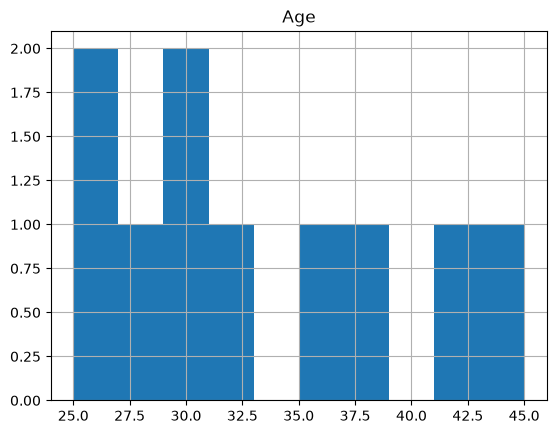

In [135]:
# lets plot a histogram for age column and see its values
df.hist("Age")

<Axes: xlabel='Age', ylabel='Salary'>

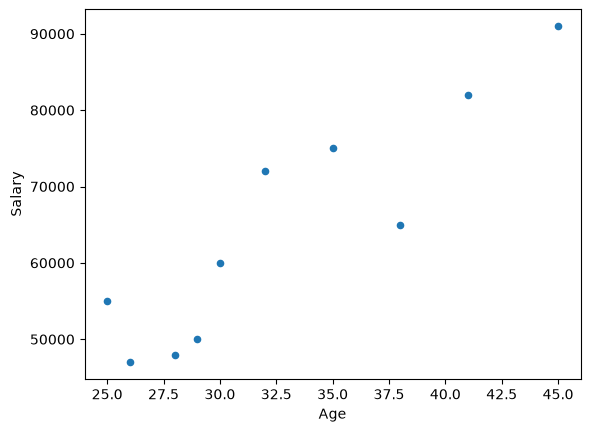

In [136]:
# we can also plot a x to y scatter points where we can see points mentioning increase in salary  with increasing age
df.plot(kind="scatter", x="Age", y="Salary")

<Axes: xlabel='temperature', ylabel='aqi'>

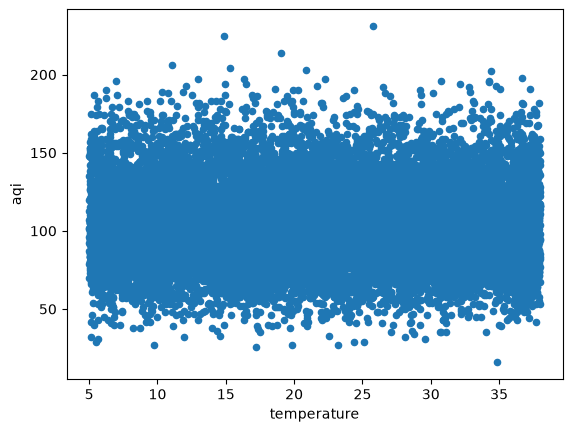

In [137]:
dt2.plot(kind="scatter", x="temperature", y="aqi")

In [138]:
# we have some data into different dataframe or tables
df_customers = pd.DataFrame({
    "Customer_id":[1, 2, 3, 4],
    "Name":["Adam", "Bob", "Charlie", "Dave"]
})

df_orders = pd.DataFrame({
    "Order_id":[101, 102, 103, 104],
    "Customer_id":[2, 1, 3, 5],
    "Amount":[250, 120, 300, 180]
})

print(df_customers)
print(df_orders)

   Customer_id     Name
0            1     Adam
1            2      Bob
2            3  Charlie
3            4     Dave
   Order_id  Customer_id  Amount
0       101            2     250
1       102            1     120
2       103            3     300
3       104            5     180


In [140]:
# to combine them so we can data based on joins that we study in sql
# first inner join 
df_inner = pd.merge(df_customers, df_orders, on="Customer_id")
df_inner # it matches the column with id and keeps only common ones from both the table

,Customer_id,Name,Order_id,Amount
0,1,Adam,102,120
1,2,Bob,101,250
2,3,Charlie,103,300


In [142]:
# now lets do left join where data of left side table preserved and if some values matches in table those are kept and others become NaN
df_left = pd.merge(df_customers, df_orders, on="Customer_id", how="left")
df_left

,Customer_id,Name,Order_id,Amount
0,1,Adam,102.0,120.0
1,2,Bob,101.0,250.0
2,3,Charlie,103.0,300.0
3,4,Dave,NaN,NaN


In [143]:
# in the same way we have right join which keeps all values of right side tables and matches it with left
# if some values are missing then we have NaN there
df_right = pd.merge(df_customers, df_orders, on="Customer_id", how="right")
df_right

,Customer_id,Name,Order_id,Amount
0,2,Bob,101,250
1,1,Adam,102,120
2,3,Charlie,103,300
3,5,NaN,104,180


In [144]:
# in the end we have our outer join which keeps all column data from both table and uses NaN for missing values
df_outer = pd.merge(df_customers, df_orders, on="Customer_id", how="outer")
df_outer

,Customer_id,Name,Order_id,Amount
0,1,Adam,102.0,120.0
1,2,Bob,101.0,250.0
2,3,Charlie,103.0,300.0
3,4,Dave,NaN,NaN
4,5,NaN,104.0,180.0


In [145]:
# now we make some more dataframes so that we can see concatenation of dataframes
dt_1 = pd.DataFrame({
    "id":[1, 2, 3],
    "name":["Alice", "Bob", "Jason"]
})

dt_2 = pd.DataFrame({
    "id":[5, 6, 4],
    "name":["Robert", "Jimme", "Warren"]
})

print(dt_1)
print(dt_2)

   id   name
0   1  Alice
1   2    Bob
2   3  Jason
   id    name
0   5  Robert
1   6   Jimme
2   4  Warren


In [147]:
# now these are separated tables but we can concatenate them on top of each other or side by side
# first on top of each other
pd.concat([dt_1, dt_2])

,id,name
0,1,Alice
1,2,Bob
2,3,Jason
0,5,Robert
1,6,Jimme
2,4,Warren


In [150]:
# here you can see that we have same labels are for different rows so to ignore them
pd.concat([dt_1, dt_2], ignore_index=True) # here we got new index

,id,name
0,1,Alice
1,2,Bob
2,3,Jason
3,5,Robert
4,6,Jimme
5,4,Warren


In [153]:
# now we can add them side by side in column wise
# for this we have to change the axis
pd.concat([dt_1, dt_2], axis=1) # this is one more way

,id,name,id,name
0,1,Alice,5,Robert
1,2,Bob,6,Jimme
2,3,Jason,4,Warren


In [ ]:
# here comes the end of lecture 2 of pandas it is completed and done